In [27]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from scripts.computations import compute_complexity, compute_assembly, compute_depth
from itertools import islice
import logging
import country_converter as coco
import plotly.express as px
import re
from matplotlib.ticker import FuncFormatter

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# museums

In [14]:
# spatial coverage map (reusable for other museum datasets)

logging.getLogger('country_converter').setLevel(logging.ERROR)  # it logs every name it can't match
# country_converter 1.3.2 misreads its own country table under pandas 3, so load the table here and pass it in
_cc_data = pd.read_csv(coco.country_converter.COUNTRY_DATA_FILE, sep='\t', keep_default_na=False, na_values=[''])
cc = coco.CountryConverter(country_data=_cc_data[_cc_data.obsolete.isna()])


def to_iso3(places, sep=',', aliases=None, levels=2):
    '''place strings -> ISO3 code of the first hierarchy level (of the first `levels`) that names a country'''
    parts = places.str.split(sep).str[:levels].apply(lambda lv: [p.strip() for p in lv])
    names = pd.Series(parts.explode().dropna().unique())
    iso = cc.pandas_convert(names, to='ISO3', not_found='NOTFOUND').set_axis(names.values)
    iso = iso.where(iso.astype(str).str.fullmatch(r'[A-Z]{3}'))
    for pattern, code in (aliases or {}).items():  # aliases win over the converter
        iso[names.str.contains(pattern, case=False, regex=True).values] = code
    return parts.apply(lambda lv: next((iso[p] for p in lv if pd.notna(iso[p])), None))


def country_map(df, place_col, base_df=None, sep=',', aliases=None, levels=2, min_n=30, title='', out_dir=None,
                show=True):
    '''Choropleth of where df's rows come from, by country.

    df        : the filtered rows (e.g. objects with a date, place, material and technique)
    place_col : place column; a hierarchy like "Iran,Susa" is read left to right, up to `levels` deep
    base_df   : optional, the whole collection df was filtered from (keep the original index).
                Adds a second map: each country's share of df / its share of base_df.
    aliases   : {regex: ISO3} for names the converter misses or gets wrong, e.g. {'alaska|arizona': 'USA'}
    min_n     : in the ratio map, countries with fewer than min_n rows in base_df are left gray
    out_dir   : folder to save the maps in (interactive html); None = only show them
    show      : False = don't draw the maps in the notebook (with out_dir, they are only saved)
    Returns the per-country table.
    '''
    pop = df if base_df is None else base_df
    iso = to_iso3(pop[place_col].dropna(), sep, aliases, levels)
    unmatched = pop.loc[iso.index[iso.isna()], place_col].str.split(sep).str[0].value_counts()
    print(f'{iso.notna().mean():.1%} of rows with a place were matched to a country. '
          f'Most common unmatched (add to aliases if they belong to one country):')
    print(unmatched.head(15).to_dict())

    tab = pd.DataFrame({'n': iso.reindex(df.index).value_counts()})
    if base_df is not None:
        tab = tab.join(iso.value_counts().rename('n_base'), how='outer').fillna({'n': 0})
    tab.index.name = 'iso3'
    tab['country'] = cc.pandas_convert(tab.index.to_series(), src='ISO3', to='name_short')
    tab['pct'] = tab.n / tab.n.sum() * 100

    geo = dict(showframe=False, showcoastlines=False, showland=True, landcolor='#c3c2b7', bgcolor='#fcfcfb',
               projection_type='natural earth', projection_rotation_lon=0, lataxis_range=[-58, 85])
    layout = dict(margin=dict(l=0, r=0, t=70, b=0), paper_bgcolor='#fcfcfb', font_color='#52514e',
                  title_font_color='#0b0b0b', height=500)
    labels = {'n': 'filtered objects', 'pct': '% of filtered', 'n_base': 'collection objects',
              'pct_base': '% of collection', 'ratio': 'ratio'}
    stem = re.sub(r'\W+', '_', title).strip('_').lower() or 'coverage'

    def finish(fig, name):
        fig.update_traces(marker_line_color='#fcfcfb', marker_line_width=.5)
        fig.update_geos(**geo).update_layout(**layout)
        if out_dir:
            Path(out_dir).mkdir(parents=True, exist_ok=True)
            fig.write_html(Path(out_dir) / f'{stem}_{name}.html')
        if show:
            fig.show()

    # map 1: counts, log color scale
    tab['log_n'] = np.log10(tab.n.where(tab.n > 0))
    ticks = [10 ** k for k in range(int(np.nanmax(tab.log_n)) + 1)]
    fig = px.choropleth(tab, locations=tab.index, color='log_n', hover_name='country', labels=labels,
                        hover_data={'log_n': False, 'n': ':,', 'pct': ':.2f'},
                        color_continuous_scale=['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'],
                        title=f'{title} objects per country<br><sup>n = {int(tab.n.sum()):,} · gray = none</sup>')
    fig.update_coloraxes(colorbar=dict(title='objects', tickvals=np.log10(ticks), ticktext=[f'{t:,}' for t in ticks]))
    finish(fig, 'map_counts')

    # map 2: representation relative to the whole collection, log2 color scale, gray midpoint = 1x
    if base_df is not None:
        tab['pct_base'] = tab.n_base / tab.n_base.sum() * 100
        tab['ratio'] = tab.pct / tab.pct_base
        tab['log2_ratio'] = np.log2(tab.ratio.where(tab.n_base >= min_n).clip(1 / 8, 8))  # 0 objects kept -> 1/8x
        fig = px.choropleth(tab, locations=tab.index, color='log2_ratio', hover_name='country', labels=labels,
                            hover_data={'log2_ratio': False, 'n': ':,', 'n_base': ':,', 'pct': ':.2f',
                                        'pct_base': ':.2f', 'ratio': ':.2f'},
                            color_continuous_scale=['#a82e2e', '#e34948', '#f2a6a2', '#f0efec', '#9ec5f4', '#2a78d6', '#184f95'],
                            range_color=[-3, 3],
                            title=f'{title} representation vs. the whole collection<br><sup>share of filtered rows ÷ share '
                                  f'of collection · red = under-, blue = over-represented · gray = fewer than {min_n} '
                                  f'objects in the collection</sup>')
        fig.update_coloraxes(colorbar=dict(title='ratio', tickvals=list(range(-3, 4)),
                                           ticktext=['≤⅛×', '¼×', '½×', '1×', '2×', '4×', '≥8×']))
        finish(fig, 'map_ratio')

    return tab.drop(columns=[c for c in ['log_n', 'log2_ratio'] if c in tab]).sort_values('n', ascending=False)

In [15]:
# temporal coverage plot (reusable for other museum datasets)

def time_dist(df, early_col, late_col=None, base_df=None, text_col=None, out_dir=None, title='', show=True):
    '''When df's objects were made (midpoint of early-late date): full range on a log axis + zoom on 5000 BCE-today.

    early_col, late_col : numeric year columns (negative = BCE); late_col=None uses early_col alone
    base_df  : optional, the whole collection df was filtered from; drawn in gray for comparison
    text_col : optional date text column; rows whose text says BCE (and not CE) get negative years,
               which fixes BCE dates stored with a positive sign
    out_dir  : folder to save the figure in (png); None = only show it
    show     : False = don't draw the figure in the notebook (with out_dir, it is only saved)
    Returns a table of date quantiles.
    '''
    now = pd.Timestamp.now().year

    def midpoints(d, name):
        e = pd.to_numeric(d[early_col], errors='coerce')
        l = e if late_col is None else pd.to_numeric(d[late_col], errors='coerce')
        if text_col:
            t = d[text_col].fillna('').astype(str)
            bce = t.str.contains(r'B\.?C') & ~t.str.contains(r'(?<!B)C\.?E\b|\bA\.?D\b')
            fixed = bce & ((e > 0) | (l > 0))
            e, l = e.where(~bce, -e.abs()), l.where(~bce, -l.abs())
            print(f'{name}: {fixed.sum():,} BCE dates stored with a positive sign were corrected')
        mid = ((e + l) / 2).dropna()
        print(f'{name}: {len(mid):,} rows with a numeric date, {(mid > now).sum():,} dated after {now} dropped')
        return mid[mid <= now]

    groups = {} if base_df is None else {'collection': midpoints(base_df, 'collection')}
    groups['filtered'] = midpoints(df, 'filtered')
    styles = {'collection': dict(color='#c3c2b7'), 'filtered': dict(histtype='step', color='#2a78d6', lw=2)}
    q = [0, .05, .25, .5, .75, .95, 1]
    summary = pd.DataFrame({k: m.quantile(q) for k, m in groups.items()}).round(0)

    fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7), facecolor='#fcfcfb', gridspec_kw={'hspace': .5})
    oldest = now - min(m.min() for m in groups.values())
    log_bins = np.logspace(0, np.log10(max(oldest, 10)) + .05, 70)
    for k, m in groups.items():
        top.hist((now - m).clip(lower=1), log_bins, weights=np.full(len(m), 100 / len(m)),
                 label=f'{k} (n = {len(m):,})', **styles[k])
        z = m[m >= -5000]
        bottom.hist(z, np.arange(-5000, now + 100, 100), weights=np.full(len(z), 100 / max(len(z), 1)),
                    label=f'{k}: {len(z) / len(m):.0%} of its dates fall in this window', **styles[k])
    top.set_xscale('log')
    top.invert_xaxis()  # oldest on the left
    top.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f'{v / 1e6:g}M' if v >= 1e6 else f'{v / 1e3:g}k' if v >= 1e4 else f'{v:,.0f}'))
    top.set_title(f'full range: years before {now} (log scale)', loc='left', fontsize=11)
    bottom.xaxis.set_major_formatter(FuncFormatter(
        lambda v, _: f'{-v:.0f} BCE' if v < 0 else f'{v:.0f} CE' if v > 0 else '0'))
    bottom.set_xticks(np.arange(-5000, now, 1000))
    bottom.set_xlim(-5000, now + 100)
    bottom.set_title('zoom: 5000 BCE to today, 100-year bins', loc='left', fontsize=11)
    for ax in (top, bottom):
        ax.set_facecolor('#fcfcfb')
        ax.set_ylabel('% of objects in each bin', color='#52514e')
        ax.grid(axis='y', color='#e1e0d9', lw=.6)
        ax.set_axisbelow(True)
        ax.tick_params(length=0, colors='#898781')
        for s in ('top', 'right', 'left'):
            ax.spines[s].set_visible(False)
        ax.spines['bottom'].set_color('#c3c2b7')
        ax.legend(frameon=False, loc='upper left', fontsize=9)
    fig.suptitle(f'{title} when objects were made (midpoint of early–late date)', x=.125, ha='left', fontsize=13)

    if out_dir:
        Path(out_dir).mkdir(parents=True, exist_ok=True)
        stem = re.sub(r'\W+', '_', title).strip('_').lower() or 'coverage'
        fig.savefig(Path(out_dir) / f'{stem}_time.png', dpi=150, bbox_inches='tight', facecolor='#fcfcfb')
    if show:
        plt.show()
    else:
        plt.close(fig)  # without this the notebook still draws the figure when the cell finishes
    return summary

### Penn

In [ ]:
penn_df = pd.read_csv('data/real/museums/penn.csv')
from scripts.scrapers.technology_filter import is_technology
penn_df = penn_df[[is_technology(t, m, q) for t, m, q in zip(penn_df.objectName, penn_df.material, penn_df.technique)]]

In [12]:
# Penn: objects with date + place + material + technique vs the whole collection
FIG_DIR = 'figures/penn'  # where the coverage figures are saved; None = don't save
SHOW_FIGS = True         # True = also draw the figures in the notebook
penn_filtered = penn_df[penn_df[['dateMade', 'placeName', 'material', 'technique']].notna().all(axis=1)]
penn_aliases = {  # names the converter misses; broad regions (Mediterranean, Africa, Borneo, ...) are left unmatched
    r'alaska|arizona|new mexico|california|colorado|utah|washington \(u|montana|oregon|ohio|wyoming|nevada|dakota|unites states': 'USA',
    'philippine': 'PHL', 'siberia': 'RUS', 'crimea': 'UKR', r'sumatra|^java|sulawesi|celebes': 'IDN', 'tibet': 'CHN',
    r'caroline islands|truk': 'FSM', 'holland': 'NLD', r'society islands|marquesas': 'PYF', 'johore': 'MYS',
    r'admiralty islands|wuvulu|^aua$': 'PNG', 'gilbert islands': 'KIR', r'beth shemesh|beth shean': 'ISR'}
penn_countries = country_map(penn_filtered, 'placeName', base_df=penn_df, aliases=penn_aliases, title='Penn:',
                             out_dir=FIG_DIR, show=SHOW_FIGS)
penn_countries.head(15)

95.0% of rows with a place were matched to a country. Most common unmatched (add to aliases if they belong to one country):
{'Mediterranean': 9807, 'Borneo': 1893, 'North America': 1278, 'Africa': 1028, 'Great Plains (Plain)': 823, 'Near East': 667, 'Europe (uncertain)': 564, 'Asia': 459, 'Europe': 458, 'South America': 264, 'West Indies': 133, 'North Africa': 120, 'Polynesia': 105, 'South Arabia': 104, 'Arabian Peninsula': 101}


,n,n_base,country,pct,pct_base,ratio
iso3,,,,,,
EGY,2190.0,46017,Egypt,14.827353,11.674316,1.270083
ITA,1647.0,7602,Italy,11.150982,1.928595,5.781920
JOR,1618.0,10189,Jordan,10.954638,2.584906,4.237926
CHN,1489.0,7639,China,10.081246,1.937982,5.201931
JPN,1070.0,4018,Japan,7.244414,1.019349,7.106900
IND,883.0,3666,India,5.978334,0.930048,6.427982
USA,812.0,82026,United States,5.497630,20.809644,0.264187
IRQ,666.0,40051,Iraq,4.509140,10.160767,0.443780
THA,501.0,1722,Thailand,3.392011,0.436864,7.764455


In [6]:
# Penn: when the filtered objects were made vs the whole collection (FIG_DIR and SHOW_FIGS are set in the map cell above)
time_dist(penn_filtered, 'earlyDate', 'lateDate', base_df=penn_df, text_col='dateMade', out_dir=FIG_DIR, title='Penn:',
          show=False)

collection: 1,975 BCE dates stored with a positive sign were corrected
collection: 97,491 rows with a numeric date, 55 dated after 2026 dropped
filtered: 272 BCE dates stored with a positive sign were corrected
filtered: 15,922 rows with a numeric date, 6 dated after 2026 dropped


,collection,filtered
0.00,-943000.0,-105250.0
0.05,-3750.0,-4250.0
0.25,-1750.0,-650.0
0.50,-500.0,300.0
0.75,1600.0,1850.0
0.95,1932.0,1958.0
1.00,2025.0,2025.0


### British Museum

In [16]:
# BM dates are text only ("144BC-143BC", "15thC-16thC", "1561 (circa)"): read them into numeric years

def _side_range(p, bc):
    '''one side of a date range -> (lo, hi, year token or None)'''
    mod = re.search(r'(?<![a-z])(early|middle|mid|late)(?![a-z])', p)
    m = re.search(r'(\d+)\s*(?:st|nd|rd|th)\s*(c|century|centuries|millenn\w*)(?![a-z])', p)
    if m:  # century or millennium, optionally its early / mid / late third
        n, size = int(m.group(1)), (1000 if m.group(2).startswith('millenn') else 100)
        lo = -n * size if bc else (n - 1) * size
        hi = lo + size - 1
        if mod:
            k = {'early': 0, 'mid': 1, 'middle': 1, 'late': 2}[mod.group(1)]
            lo, hi = lo + k * size // 3, lo + (k + 1) * size // 3 - 1
        return lo, hi, None
    m = re.search(r'(\d{2,4})s(?![a-z])', p)  # decade: "1930s"
    if m:
        y = int(m.group(1))
        return (-y - 9, -y, None) if bc else (y, y + 9, None)
    nums = re.findall(r'\d+', p)
    tok = nums[-1] if re.search(r'jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec', p) else nums[0]  # "9 March 1890"
    y = -int(tok) if bc else int(tok)
    return y, y, tok


def bm_date_range(text):
    '''BM "Production date" text -> (early, late) years, negative = BC; NaNs if no year can be read.
    Reads years, "A-B" ranges, BC/AD, centuries and millennia (with early / mid / late) and decades.
    Notes in brackets are ignored: (circa), (AH 1250), (before 1873).'''
    s = re.sub(r'\(\s*(early|mid|middle|late)\s*\)', r' \1', text.lower())  # "19thC(early)" keeps its modifier
    s = re.sub(r'\([^)]*\)', ' ', s)
    s = re.sub(r'(early|mid|middle|late)-', r'\1 ', s)  # "mid-19thC" is not a range
    sides = [p for p in s.split('-') if re.search(r'\d', p)]
    if not sides:
        return np.nan, np.nan
    left, right = sides[0], sides[-1]
    unit = re.search(r'(?:st|nd|rd|th)\s*(c|century|centuries|millenn\w*)(?![a-z])', right)
    if unit and not re.search(r'(?:st|nd|rd|th)\s*(c|century|centuries|millenn\w*)(?![a-z])', left):
        left = re.sub(r'(\d+\s*(?:st|nd|rd|th))(?![a-z])', r'\1 ' + unit.group(1), left)  # "20th-21st century"
    is_bc = lambda p: bool(re.search(r'(?<![a-z])bce?(?![a-z])|b\.c\.', p))
    is_ad = lambda p: bool(re.search(r'(?<![a-z])(ad|ce)(?![a-z])|a\.d\.', p))
    right_bc = is_bc(right)
    left_bc = is_bc(left) or (right_bc and not is_ad(left))  # "1200-1100BC": both BC; "27BC-14": only the start is
    lo1, hi1, t1 = _side_range(left, left_bc)
    lo2, hi2, t2 = _side_range(right, right_bc)
    if t1 and t2 and not (left_bc or right_bc) and len(t2) < len(t1) and int(t2) < int(t1):  # "1850-60"
        lo2 = hi2 = int(t1[:len(t1) - len(t2)] + t2)
    now = pd.Timestamp.now().year  # "21stC" ends in 2099; cap at this year
    return min(lo1, lo2, now), min(max(hi1, hi2), now)

In [17]:
bm_df = pd.read_csv('data/real/museums/bm.csv', low_memory=False)
FIG_DIR = 'figures/bm'  # where the coverage figures are saved; None = don't save
SHOW_FIGS = True         # True = also draw the figures in the notebook
# place = production place if the record has one, else find spot (origin preferred, as for Penn)
has_prod = bm_df.productionPlace.notna()
bm_df['place'] = bm_df.productionPlace.where(has_prod, bm_df.findSpot)
bm_df['country'] = bm_df.productionCountry.where(has_prod, bm_df.findSpotCountry)
# read each distinct date text into years once, then join back
bm_years = pd.DataFrame([bm_date_range(s) for s in bm_df.dateMade.dropna().unique()],
                        index=bm_df.dateMade.dropna().unique(), columns=['earlyDate', 'lateDate'])
bm_df = bm_df.join(bm_years, on='dateMade')
print(f"date text read into years: {bm_df.earlyDate.notna().sum() / bm_df.dateMade.notna().sum():.2%}")
bm_filtered = bm_df[bm_df[['dateMade', 'place', 'material', 'technique']].notna().all(axis=1)]
print(f"date + place + material + technique: {len(bm_filtered) / len(bm_df):.2%} ({len(bm_filtered):,} rows)")

date text read into years: 99.99%
date + place + material + technique: 31.93% (538,620 rows)


In [18]:
# space
# countries are the BM place thesaurus's labels; these are the ones country_converter misses
bm_aliases = {r'^(scotland|wales|northern ireland)$': 'GBR', r'malaya|straits settlements': 'MYS', 'sénégal': 'SEN',
              'madeira': 'PRT', r'andalus|ceuta': 'ESP', 'sikkim': 'IND', 'portuguese guinea': 'GNB',
              'west germany': 'DEU', 'north vietnam': 'VNM', 'sakha': 'RUS'}  # historic states (Macedon, Yugoslavia, Parthia, ...) stay unmatched
print(f"{(bm_df.place.notna() & bm_df.country.isna()).mean():.1%} of rows have a place but no modern country "
      f"(historic states and regions: Gaul, Roman Empire, British Isles, ...)")
bm_countries = country_map(bm_filtered, 'country', base_df=bm_df, sep=';', levels=1, aliases=bm_aliases, title='BM:',
                           out_dir=FIG_DIR, show=SHOW_FIGS)
bm_countries.head(15)

6.7% of rows have a place but no modern country (historic states and regions: Gaul, Roman Empire, British Isles, ...)


C:\Users\User\AppData\Local\Temp\ipykernel_4884\2303137743.py:16: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  iso[names.str.contains(pattern, case=False, regex=True).values] = code


99.8% of rows with a place were matched to a country. Most common unmatched (add to aliases if they belong to one country):
{'Macedon': 1673, 'Yugoslavia': 530, 'Parthia': 157, 'Nabataea': 79, 'Prussia': 61, 'Netherlands Antilles': 45, 'Rhodesia and Nyasaland': 41, 'Dutch West Indies': 15, 'Danish West Indies': 9, 'Gilbert and Ellice Islands': 2, 'Lotharingia': 2, 'Brigham City': 1, 'Umm al-Qaiwain': 1, 'Yan State': 1, 'Dilmun': 1}


,n,n_base,country,pct,pct_base,ratio
iso3,,,,,,
GBR,159248.0,267883,United Kingdom,31.698967,23.147159,1.369454
FRA,32977.0,56751,France,6.564207,4.903725,1.338617
JPN,31486.0,38251,Japan,6.267417,3.305182,1.896240
CHN,26225.0,51448,China,5.220194,4.445504,1.174264
ITA,24644.0,121015,Italy,4.905489,10.456630,0.469127
GRC,20985.0,46485,Greece,4.177150,4.016663,1.039955
IRQ,20037.0,31457,Iraq,3.988447,2.718128,1.467351
DEU,17289.0,71109,Germany,3.441446,6.144367,0.560098
EGY,11702.0,43112,Egypt,2.329331,3.725210,0.625289


In [19]:
# time
# the parsed years already carry the BC sign, so no text_col (it would also flip the AD end of "27BC-14")
time_dist(bm_filtered, 'earlyDate', 'lateDate', base_df=bm_df, out_dir=FIG_DIR, title='BM:', show=False)

collection: 1,669,300 rows with a numeric date, 0 dated after 2026 dropped
filtered: 538,605 rows with a numeric date, 0 dated after 2026 dropped


,collection,filtered
0.00,-800000.0,-40000.0
0.05,-500.0,-1300.0
0.25,625.0,1200.0
0.50,1760.0,1791.0
0.75,1862.0,1860.0
0.95,1980.0,1980.0
1.00,2026.0,2026.0


# toy/test

## individual scores

In [28]:
# setup
la_path = Path('data/toy/little_alchemy_2')
ohol_path = Path('data/toy/one_hour_one_life')
mc_path = Path('data/toy/minecraft')

la2_c_df = compute_complexity(la_path / 'recipes_edgelist.csv')
ohol_c_df = compute_complexity(ohol_path / 'recipes_edgelist.csv')
mc_c_df = compute_complexity(mc_path / 'recipes_edgelist.csv')

la2_d_df = compute_depth(la_path / 'recipes_default.csv')
ohol_d_df = compute_depth(ohol_path / 'recipes_default.csv')
mc_d_df = compute_depth(mc_path / 'recipes_default.csv')

la2_a_df = compute_assembly(la_path / 'assembly_edgelist.csv')
ohol_a_df = compute_assembly(ohol_path / 'assembly_edgelist.csv')
mc_a_df = compute_assembly(mc_path / 'assembly_edgelist.csv')

In [ ]:
# sample to check against hand computations
print(la2_a_df.sort_values(by='Assembly').head(5))

#### checks
All three scores are recomputed from each game's recipe table (`result,input_1,input_2`, or up to `input_10` for Minecraft, whose recipes use many inputs at once), so the robustness tests can drop recipes or items in memory and rerun the same functions.

In [ ]:
from io import StringIO

METRICS = ['complexity', 'depth', 'assembly']
games = {'LA2': la_path, 'OHOL': ohol_path, 'MC': mc_path}
recipes = {g: pd.read_csv(p / 'recipes_default.csv') for g, p in games.items()}

def inputs(r):
    '''each recipe's inputs as a list (Minecraft's unused input columns are blank)'''
    return [[x for x in row if isinstance(x, str)] for row in r.filter(like='input_').itertuples(index=False)]

def as_files(r):
    '''recipe table -> in-memory versions of the three files the compute functions read.
    assembly: one edge per distinct input, partner = the other inputs joined by '+' (a + a -> z gives a,z,a)'''
    asm = pd.DataFrame([(s, z, '+'.join(ins[:k] + ins[k + 1:]))
                        for z, ins in zip(r.result, inputs(r)) for k, s in enumerate(ins) if s not in ins[:k]],
                       columns=['input', 'result', 'partner'])
    buf = lambda df, header=False: StringIO(df.to_csv(index=False, header=header, lineterminator='\n'))
    return buf(asm[['input', 'result']].drop_duplicates()), buf(r, True), buf(asm)

def scores(r):
    edges, table, asm = as_files(r)
    return pd.DataFrame({'complexity': compute_complexity(edges).set_index('Tech')['Complexity'],
                         'depth': compute_depth(table).set_index('Tech')['Depth'],
                         'assembly': compute_assembly(asm).set_index('Tech')['Assembly']})

S = {g: scores(r) for g, r in recipes.items()}

### 1. metrics against each other
Diagonal: each score's distribution. Off-diagonal: pairs of scores. Both on a log10(score + 1) scale. ρ is Spearman (rank) correlation, since the relationships are monotone but not linear.

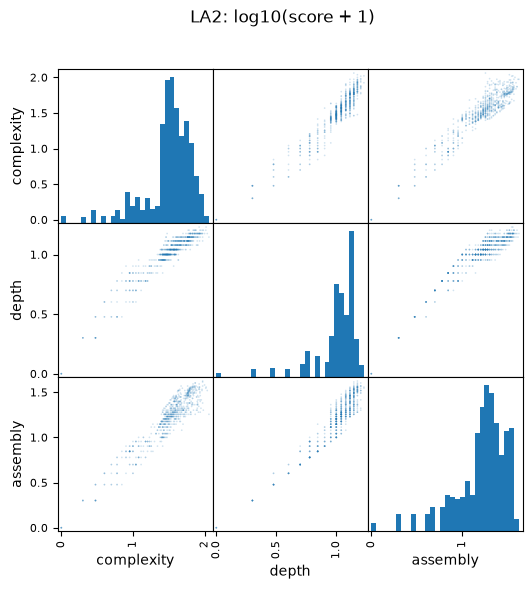

,median,max,skew,ρ complexity,ρ depth,ρ assembly
complexity,35.0,114.0,0.56,1.00,0.91,0.88
depth,10.0,16.0,-0.84,0.91,1.00,0.88
assembly,17.0,41.0,0.18,0.88,0.88,1.00


assembly rank << depth rank: ['Vampire', 'Warrior', 'Excalibur'] 
assembly rank >> depth rank: ['Watch', 'Don Quixote', 'Idea']


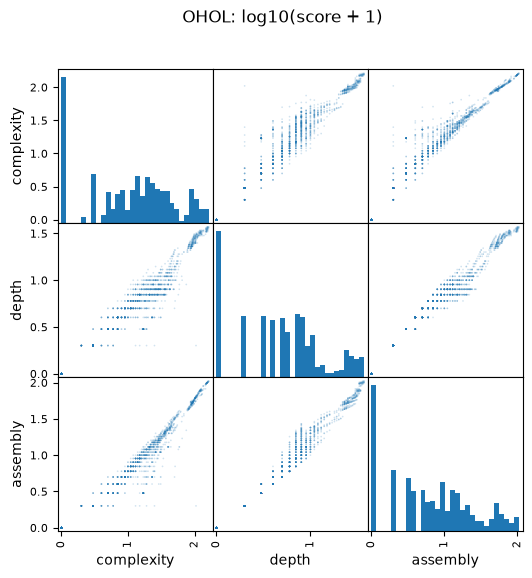

,median,max,skew,ρ complexity,ρ depth,ρ assembly
complexity,12.0,163.0,1.97,1.00,0.96,0.97
depth,4.0,36.0,1.76,0.96,1.00,0.98
assembly,6.0,104.0,2.23,0.97,0.98,1.00


assembly rank << depth rank: ['Pit Stakes', 'Cut Stones with Bear Skin', 'Unstable Bell Tower Base'] 
assembly rank >> depth rank: ['Green Bowler Hat with Yellow Rose', 'Red Bowler Hat with Green Rose', 'Green Bowler Hat']


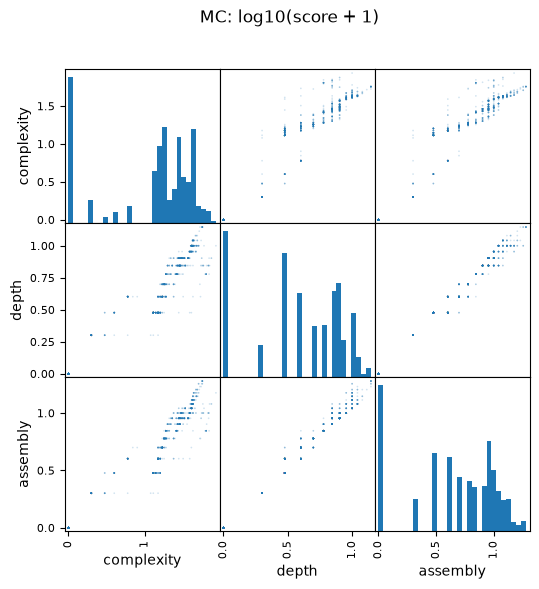

,median,max,skew,ρ complexity,ρ depth,ρ assembly
complexity,17.0,85.0,0.55,1.00,0.95,0.96
depth,4.0,13.0,0.33,0.95,1.00,0.98
assembly,5.0,18.0,0.50,0.96,0.98,1.00


assembly rank << depth rank: ['Yellow Shulker Box', 'Bamboo Mosaic Slab', 'White Shulker Box'] 
assembly rank >> depth rank: ['Black Harness', 'Purple Harness', 'Rabbit Stew']


In [30]:
for g, s in S.items():
    pd.plotting.scatter_matrix(np.log10(s + 1), figsize=(6, 6), alpha=.2, s=6, hist_kwds={'bins': 30})
    plt.suptitle(f'{g}: log10(score + 1)')
    plt.show()
    display(pd.concat([s.agg(['median', 'max', 'skew']).T, s.corr('spearman').add_prefix('ρ ')], axis=1).round(2))
    # where the two pathway-based scores disagree most (rank percentile gap, craftable items)
    gap = s[s.depth > 0].rank(pct=True).pipe(lambda k: k.assembly - k.depth).sort_values()
    print('assembly rank << depth rank:', list(gap.index[:3]), '\nassembly rank >> depth rank:', list(gap.index[-3:]))

### 2. validity (OHOL and Minecraft)
LA2's data has no independent complexity measure (only name, letter and recipe count), so this section covers OHOL and Minecraft.

#### OHOL
**What we know here that we won't for real technologies**
- The complete recipe set, so a missing recipe is a choice we made by filtering, not an unknown.
- The true starting items (`natural` means the item spawns on the map).
- `game_depth`: the game engine's own depth, computed over *every* transition, including the steps the tech tree filtered out.
- Development order (object IDs are assigned in creation order). The real-world analogue, invention or patent dates, is partly knowable, so this is the more realistic check.

**Basal problem.** 347 of OHOL's 413 starting items aren't natural. They're starting items only because their production steps were filtered out, and their `game_depth` averages 44. Every score counts up from those items, while `game_depth` counts up from natural items. To put both on the same baseline, `game_depth` is re-based by subtracting the `game_depth` of the highest starting item the item is built on. Starting items themselves are left out, since every score is 0 for them by definition.

,game_depth,game_depth_rebased,dev_order
complexity,0.55,0.69,0.26
depth,0.54,0.71,0.22
assembly,0.56,0.73,0.26


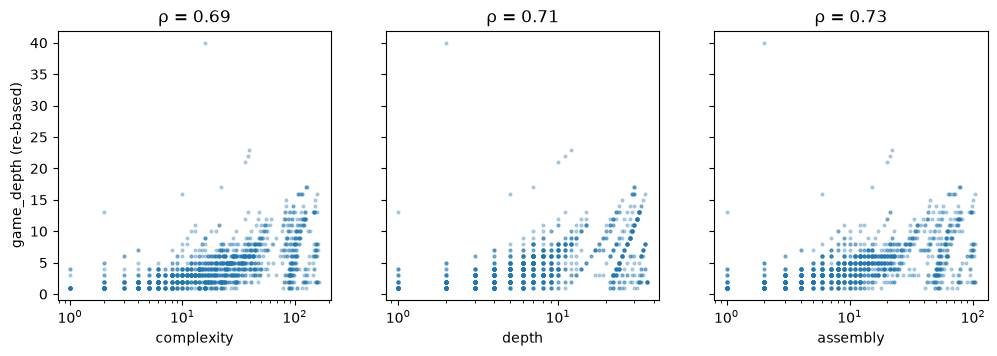

In [31]:
o = pd.read_csv(ohol_path / 'items.csv').set_index('item')
G = nx.read_edgelist(ohol_path / 'recipes_edgelist.csv', delimiter=',', create_using=nx.DiGraph)
starts = set(o.index[o.base == 1])
o['start_depth'] = [max((o.game_depth[b] for b in nx.ancestors(G, n) & starts), default=o.game_depth[n]) for n in o.index]
o['game_depth_rebased'] = o.game_depth - o.start_depth
o['dev_order'] = o.object_ids.astype(str).str.split().apply(lambda ids: min(map(int, ids)))

v = S['OHOL'].join(o)[lambda d: d.base == 0]
display(pd.DataFrame({p: v[METRICS].corrwith(v[p], method='spearman')
                      for p in ['game_depth', 'game_depth_rebased', 'dev_order']}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, m in zip(axes, METRICS):
    ax.scatter(v[m], v.game_depth_rebased, s=4, alpha=.3)
    ax.set(xscale='log', xlabel=m, title=f'ρ = {v[m].corr(v.game_depth_rebased, method="spearman"):.2f}')
axes[0].set_ylabel('game_depth (re-based)')
plt.show()

#### Minecraft
**What we know here**
- Mojang's complete recipe files, plus which tool each gathered item needs, so the true starting items (`raw`): blocks and animals as found in the world, marked `(in world)`, and whatever is gathered by hand (logs, sand, flowers, mob drops).
- Equipment tiers, which every player learns. Tools go wooden < stone < copper < iron < diamond < netherite, and armor goes leather < copper < iron < diamond < netherite. Scores should rise with the tier within each family (Pickaxe, Axe, ..., Boots). This only works because mining needs the right pickaxe (Diamond Ore needs an Iron Pickaxe): without it, Diamond would be a starting item and diamond gear would score like wooden gear. Golden gear is left out, since it's a weak tier made from a mid-game metal. Chainmail has no recipe. Copper and iron are expected to tie, since both are mined with a Stone Pickaxe and smelted.
- No development order: Mojang's files don't record when each item was added.

`game_depth` is depth over *every* recipe, including the one-input steps the network leaves out (log → planks, flower → dye). Those steps are the only difference, so its agreement with `depth` is close to guaranteed. It mainly shows how much leaving them out matters. It's re-based the same way as OHOL's: 28 of Minecraft's 215 starting items aren't raw (the planks, the dyes, Sugar, Bone Meal and Blaze Powder).

In [32]:
mc_items = pd.read_csv(mc_path / 'items.csv').set_index('item')
G = nx.read_edgelist(mc_path / 'recipes_edgelist.csv', delimiter=',', create_using=nx.DiGraph)
starts = set(mc_items.index[mc_items.base == 1])
mc_items['start_depth'] = [max((mc_items.game_depth[b] for b in nx.ancestors(G, n) & starts), default=mc_items.game_depth[n])
                           for n in mc_items.index]
mc_items['game_depth_rebased'] = mc_items.game_depth - mc_items.start_depth

v = S['MC'].join(mc_items)[lambda d: d.base == 0]
display(pd.DataFrame({p: v[METRICS].corrwith(v[p], method='spearman')
                      for p in ['game_depth', 'game_depth_rebased']}).round(2))

# equipment tiers: mean score per tier, then per family the rank correlation with the tier
# and the share of tier steps (wooden -> stone, stone -> copper, ...) where the score goes up
TIERS = {'tools': ['Wooden', 'Stone', 'Copper', 'Iron', 'Diamond', 'Netherite'],
         'armor': ['Leather', 'Copper', 'Iron', 'Diamond', 'Netherite']}
FAMILIES = {'tools': ['Pickaxe', 'Axe', 'Shovel', 'Hoe', 'Sword', 'Spear'],
            'armor': ['Helmet', 'Chestplate', 'Leggings', 'Boots']}
tiers = pd.DataFrame([{'kind': k, 'family': f, 'tier': t, 'tier_rank': i, **S['MC'].loc[f'{t} {f}']}
                      for k, fams in FAMILIES.items() for f in fams for i, t in enumerate(TIERS[k])])
display(tiers.groupby(['kind', 'tier'], sort=False)[METRICS].mean().round(1))

fam = tiers.groupby(['kind', 'family'])
rho = pd.DataFrame({m: fam[[m, 'tier_rank']].apply(lambda d: d[m].corr(d.tier_rank, method='spearman'))
                    for m in METRICS})
up = pd.DataFrame({m: fam[[m, 'tier_rank']].apply(lambda d: (np.diff(d.sort_values('tier_rank')[m]) > 0).mean())
                   for m in METRICS})
display(pd.concat({'ρ with tier': rho, 'share of tier steps up': up}, axis=1).groupby('kind').mean().round(2))

,game_depth,game_depth_rebased
complexity,0.91,0.91
depth,0.99,0.98
assembly,0.96,0.96


complexity  depth  assembly
kind  tier                                  
tools Wooden           14.0    2.0       3.0
      Stone            23.0    4.0       5.0
      Copper           32.0    7.0       8.0
      Iron             36.0    7.0       8.0
      Diamond          40.0    9.0      10.0
      Netherite        55.8   13.0      17.8
armor Leather          14.0    2.0       3.0
      Copper           32.0    7.0       8.0
      Iron             36.0    7.0       8.0
      Diamond          40.0    9.0      10.0
      Netherite        56.0   13.0      18.0

ρ with tier                share of tier steps up               
       complexity depth assembly             complexity depth assembly
kind                                                                  
armor         1.0  0.97     0.97                    1.0  0.75     0.75
tools         1.0  0.99     0.99                    1.0  0.80     0.80

### 3. robustness
Drop a fraction of the recipes or of the craftable items (a dropped item takes every recipe that uses or makes it), recompute, and compare with the full-data scores on the items that are left (Spearman ρ, mean of 10 runs). Starting items are never dropped. The biased runs make deep items (above median depth) 4× as likely to go missing as shallow ones, or the reverse. `new_basals` counts items that lose all inputs.

In [ ]:
rng = np.random.default_rng(0)

def drop(r, frac, unit, w=None):
    '''remove frac of the recipes or craftable items, sampled in proportion to item weights w'''
    pool = r.index if unit == 'recipes' else pd.Index(r.result.unique())
    p = None if w is None else w.reindex(r.result if unit == 'recipes' else pool).to_numpy(float)
    gone = rng.choice(pool, int(frac * len(pool)), replace=False, p=None if p is None else p / p.sum())
    return r.drop(gone) if unit == 'recipes' else r[~r.isin(gone).any(axis=1)]  # every column is the result or an input

def robustness(g, fracs=(.05, .1, .2, .3, .5), reps=10):
    r, base = recipes[g], S[g]
    deep = (base.depth > base.depth[base.depth > 0].median()).astype(int)
    scenarios = {'random recipes': ('recipes', None), 'random items': ('items', None),
                 'deep items 4x': ('items', 1 + 3 * deep), 'shallow items 4x': ('items', 4 - 3 * deep)}
    rows = []
    for name, (unit, w) in scenarios.items():
        for f in fracs:
            for _ in range(reps):
                s = scores(drop(r, f, unit, w))
                b = base.loc[s.index]
                rows.append({'scenario': name, 'frac': f, **s.corrwith(b, method='spearman'),
                             'new_basals': ((s.depth == 0) & (b.depth > 0)).sum()})
    return pd.DataFrame(rows)

rob = {g: robustness(g) for g in games}

In [ ]:
fig, axes = plt.subplots(len(rob), 4, figsize=(15, 3 * len(rob)), sharex=True, sharey=True)
for row, (g, res) in zip(axes, rob.items()):
    for ax, (name, d) in zip(row, res.groupby('scenario', sort=False)):
        d.groupby('frac')[METRICS].mean().plot(ax=ax, marker='o', legend=False, title=f'{g}: {name}')
    row[0].set_ylabel('ρ with full data')
axes[0, 0].legend()
plt.tight_layout()
plt.show()
# at 20% removed
display(pd.concat({g: res[res.frac == .2].groupby('scenario', sort=False)[METRICS + ['new_basals']].mean()
                   for g, res in rob.items()}).round(2))

#### Minecraft: recipe detail
Real technology records may list the materials but not the tools or workshops used, or not the quantities. Two versions of the Minecraft recipes are scored once each and compared with the full data on the items that are left:
- **without stations**: the Crafting Table, Furnace, Stonecutter, etc. are removed from every recipe. Recipes left with one input (all smelting, stonecutting and campfire cooking) are dropped, so their results become starting items or disappear. The recipe table can't tell a station from an ingredient, so the four recipes that use one as a real ingredient lose it too (the Furnace in Blast Furnace, Smoker and Furnace Minecart, and the Crafting Table in Crafter). Gathering tools (pickaxes, shears, ...) aren't stations, so they stay.
- **each input once**: copies are collapsed, so 3 Iron Ingots + 2 Sticks counts as Iron Ingot + Stick. A recipe made only of copies of one item keeps two (4 Planks → Crafting Table becomes Planks + Planks). None of the three scores should change: complexity and depth never counted copies, and assembly counts each item it builds once (reuse), however many copies a recipe needs. So this row is a check that quantities don't leak into the scores.

`median change` is the median of (new score − full-data score).

In [ ]:
STATIONS = set(pd.read_csv(mc_path / 'items.csv').query('station == 1').item)

def rebuild(r, keep):
    '''apply keep (a recipe's inputs -> the inputs to keep) to every recipe; drop recipes left with < 2 inputs'''
    out = pd.DataFrame([(z, *ins) for z, ins in zip(r.result, map(keep, inputs(r))) if len(ins) >= 2])
    return out.set_axis(['result'] + [f'input_{k}' for k in range(1, out.shape[1])], axis=1)

variants = {'without stations': lambda ins: [i for i in ins if i not in STATIONS],
            'each input once': lambda ins: list(dict.fromkeys(ins)) if len(set(ins)) > 1 else ins[:2]}
detail = {}
for name, keep in variants.items():
    r2 = rebuild(recipes['MC'], keep)
    s2 = scores(r2)
    b = S['MC'].loc[s2.index]
    detail[name] = {**s2.corrwith(b, method='spearman'), **(s2 - b).median().add_prefix('median change '),
                    'recipes left': len(r2), 'items left': len(s2), 'new_basals': ((s2.depth == 0) & (b.depth > 0)).sum()}
display(pd.DataFrame(detail).T.round(2))